In [ ]:
import torch
import torchvision
from torchvision.transforms import v2
from torchvision import models
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
import time
import os
from tempfile import TemporaryDirectory

# Setup device for GPU acceleration
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(f"Using {device} device")

Using cuda:0 device


In [ ]:
# For training: resizes to 224 and adds data augmentation
train_transform = v2.Compose([
    v2.RandomResizedCrop(224),
    v2.RandomHorizontalFlip(),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# For testing: resizes to 224 and crops
test_transform = v2.Compose([
    v2.Resize(256),
    v2.CenterCrop(224),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

batch_size = 16

# Apply train_transform
trainset = torchvision.datasets.CIFAR10(root='./data', train=True, download=True, transform=train_transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=0)

# Apply test_transform
testset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=test_transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=0)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

# Dictionary format for the training loop
dataloaders = {'train': trainloader, 'val': testloader}
dataset_sizes = {'train': len(trainset), 'val': len(testset)}

100%|██████████| 170M/170M [29:17<00:00, 97.0kB/s]


Module Construction

In [ ]:
# Load pre-trained ResNet18
net = models.resnet18(weights='IMAGENET1K_V1')

# Replace the final fully connected layer to match CIFAR-10's 10 classes
num_ftrs = net.fc.in_features
net.fc = nn.Linear(num_ftrs, 10)

# Move the network to the GPU
net = net.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 202MB/s]


Defining Loss function and optimizer

In [ ]:
criterion = nn.CrossEntropyLoss()

# Optimize all parameters in the network
optimizer = optim.SGD(net.parameters(), lr=0.001, momentum=0.9)

# Decay Learning Rate by a factor of 0.1 every 7 epochs
scheduler = lr_scheduler.StepLR(optimizer, step_size=7, gamma=0.1)

Module Training

In [ ]:
from tqdm.auto import tqdm # Import tqdm for progress bars

# Initialize lists to track metrics for your graphing cell
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []
num_epochs = 20

since = time.time()
best_acc = 0.0

# Create a temporary directory to save training checkpoints
tempdir = TemporaryDirectory()
best_model_params_path = os.path.join(tempdir.name, 'best_model_params.pt')
torch.save(net.state_dict(), best_model_params_path)

for epoch in range(num_epochs):
    print(f'Epoch {epoch+1}/{num_epochs}')
    print('-' * 10)

    # Training and validation phase
    for phase in ['train', 'val']:
        if phase == 'train':
            net.train()  # Set model to training mode
        else:
            net.eval()   # Set model to evaluate mode

        running_loss = 0.0
        running_corrects = 0

        # Iterate over data with a progress bar
        for inputs, labels in tqdm(dataloaders[phase], desc=f'{phase} Epoch {epoch+1}'):
            # Move data to GPU
            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            # Forward pass
            with torch.set_grad_enabled(phase == 'train'):
                outputs = net(inputs)
                _, preds = torch.max(outputs, 1)
                loss = criterion(outputs, labels)

                # Backward pass + optimize only if in training phase
                if phase == 'train':
                    loss.backward()
                    optimizer.step()

            # Statistics
            running_loss += loss.item() * inputs.size(0)
            running_corrects += torch.sum(preds == labels.data).item()

        if phase == 'train':
            scheduler.step()

        epoch_loss = running_loss / dataset_sizes[phase]
        epoch_acc = (running_corrects / dataset_sizes[phase]) * 100

        print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.2f}%')

        # Track metrics for your plots
        if phase == 'train':
            train_losses.append(epoch_loss)
            train_accuracies.append(epoch_acc)
        else:
            val_losses.append(epoch_loss)
            val_accuracies.append(epoch_acc)

        # Save the model if it's the best one so far
        if phase == 'val' and epoch_acc > best_acc:
            best_acc = epoch_acc
            torch.save(net.state_dict(), best_model_params_path)

    print()

time_elapsed = time.time() - since
print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
print(f'Best val Acc: {best_acc:4f}%')

# Load best model weights for evaluation
net.load_state_dict(torch.load(best_model_params_path, weights_only=True))
tempdir.cleanup()

Epoch 1/20
----------


train Epoch 1:   0%|          | 0/3125 [00:00<?, ?it/s]

train Loss: 0.9313 Acc: 67.74%


val Epoch 1:   0%|          | 0/625 [00:00<?, ?it/s]

val Loss: 0.3197 Acc: 88.70%

Epoch 2/20
----------


train Epoch 2:   0%|          | 0/3125 [00:00<?, ?it/s]

... (71 outputs left out)

train Epoch 20:   0%|          | 0/3125 [00:00<?, ?it/s]

train Loss: 0.3703 Acc: 87.27%


val Epoch 20:   0%|          | 0/625 [00:00<?, ?it/s]

val Loss: 0.1237 Acc: 95.82%

Training complete in 97m 22s
Best val Acc: 95.820000%


Model Evaluation

In [ ]:
correct = 0
total = 0
with torch.no_grad():
    for data in testloader:
        images, labels = data
        images = images.to(device)
        labels = labels.to(device)
        outputs = net(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 10000 test images: {100 * correct // total} %')

Accuracy of the network on the 10000 test images: 95 %


In [ ]:
# prepare to count predictions for each class
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

with torch.no_grad():
    for data in testloader:
        images, labels = data
        images = images.to(device)
        labels = labels.to(device)
        outputs = net(images)
        _, predictions = torch.max(outputs, 1)
        # collect the correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


# print accuracy for each class
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: plane is 96.3 %
Accuracy for class: car   is 98.3 %
Accuracy for class: bird  is 94.9 %
Accuracy for class: cat   is 89.2 %
Accuracy for class: deer  is 95.9 %
Accuracy for class: dog   is 94.1 %
Accuracy for class: frog  is 98.2 %
Accuracy for class: horse is 96.9 %
Accuracy for class: ship  is 97.8 %
Accuracy for class: truck is 96.6 %


Confusion matrix

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Collect all true labels and model predictions
all_preds = []
all_labels = []

with torch.no_grad():
    for data in testloader:
        images, labels = data
        images = images.to(device)
        labels = labels.to(device)
        outputs = net(images)
        _, predictions = torch.max(outputs, 1)
        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Generate and plot the confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes, yticklabels=classes)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

Sample Predictions


In [ ]:
import torchvision

# Helper function to un-normalize and display an image
def imshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

# Get a single batch of test data
dataiter = iter(testloader)
images, labels = next(dataiter)

# Display the images
imshow(torchvision.utils.make_grid(images.cpu()))

# Print the true labels
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

# Move the images to the GPU BEFORE passing to the network
images = images.to(device)

# Get predictions
outputs = net(images)
_, predicted = torch.max(outputs, 1)

print('Predicted:   ', ' '.join(f'{classes[predicted[j]]:5s}' for j in range(4)))

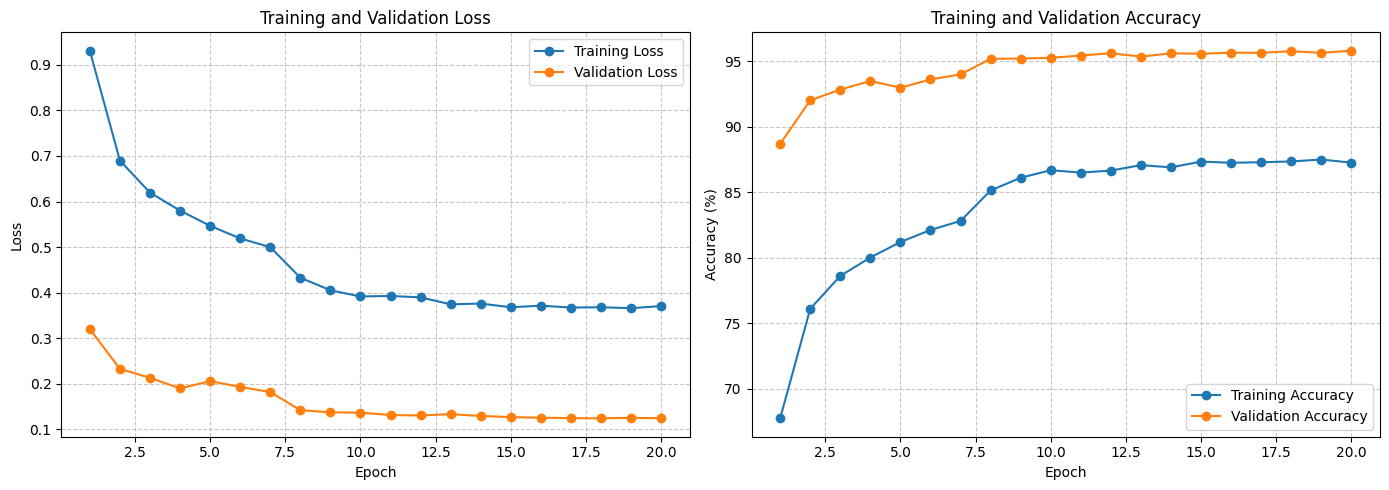

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)
plt.figure(figsize=(14, 5))

# Plot Loss Curve
plt.subplot(1, 2, 1)
plt.plot(epochs, train_losses, label='Training Loss', marker='o')
plt.plot(epochs, val_losses, label='Validation Loss', marker='o')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

# Plot Accuracy Curve
plt.subplot(1, 2, 2)
plt.plot(epochs, train_accuracies, label='Training Accuracy', marker='o')
plt.plot(epochs, val_accuracies, label='Validation Accuracy', marker='o')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

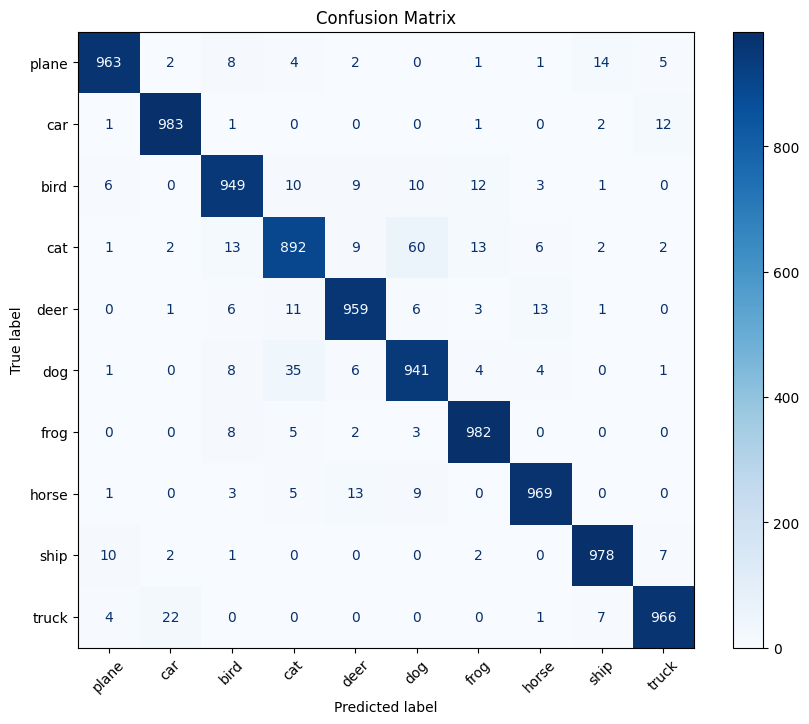

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Collect all true labels and model predictions
all_preds = []
all_labels = []

with torch.no_grad():
    for data in testloader:
        images, labels = data
        images = images.to(device)
        labels = labels.to(device)
        outputs = net(images)
        _, predictions = torch.max(outputs, 1)
        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Generate and plot the confusion matrix using Scikit-Learn's native display
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(10, 8))

# Configure and draw the plot
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
disp.plot(cmap='Blues', ax=ax, xticks_rotation=45, values_format='d')

plt.title('Confusion Matrix')
plt.show()

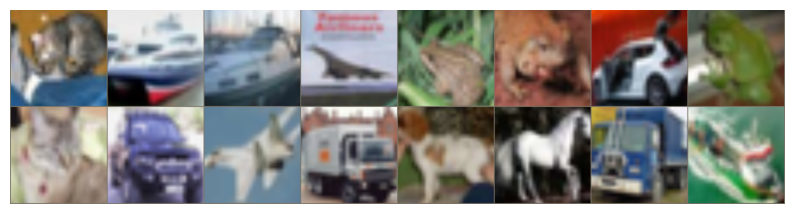

GroundTruth:  cat   ship  ship  plane
Predicted:    cat   ship  ship  plane


In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import torchvision

# ImageNet normalization values used during data loading
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

# Updated helper function to un-normalize and display an image
def imshow_correct(img):
    npimg = img.numpy()
    # Transpose from (Color, Height, Width) to (Height, Width, Color)
    npimg = np.transpose(npimg, (1, 2, 0))
    # Un-normalize using ImageNet standard deviation and mean
    npimg = std * npimg + mean
    # Clip values to stay between 0 and 1 for perfect rendering
    npimg = np.clip(npimg, 0, 1)

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.imshow(npimg)
    ax.axis('off')
    plt.show()

# Get a single batch of test data
dataiter = iter(testloader)
images, labels = next(dataiter)

# Display the images properly
imshow_correct(torchvision.utils.make_grid(images.cpu()))

# Print the true labels
print('GroundTruth: ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

# Move the images to the GPU BEFORE passing to the network
images = images.to(device)

# Get predictions
outputs = net(images)
_, predicted = torch.max(outputs, 1)

print('Predicted:   ', ' '.join(f'{classes[predicted[j]]:5s}' for j in range(4)))